<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/4_Lobes_Fully_in_Google_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2025)

Open Access (CC-BY-4.0)

# Four-Lobe CPW Test Chip

Quantum Metal builds a centered coplanar waveguide (CPW) through-line with four alternating lobes on an 8 × 4 mm chip, in which two native `LaunchpadWirebond` components connect directly to the route endpoints. A native `RouteAnchors` supplies the circular bends, and the native GDS renderer creates the positive metal mask, ground plane, cheesing, and component keep-outs.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip X size (`CHIP_SIZE_X`) | 8 mm |
| Chip Y size (`CHIP_SIZE_Y`) | 4 mm |
| GDS layer | 1, positive CPW metal and coplanar ground |
| CPW trace width and gap | 10 µm and 6 µm |
| Lobe count (`N_LOBES`) | 4, alternating down, up, down, up |
| Circular bend radius (`BEND_RADIUS`) | 110 µm |
| Straight step before each lobe (`LOBE_STEP`) | 175 µm, equal to $395-2(110)$ µm |
| Lobe horizontal repeat distance | $175+4(110)=615$ µm |
| Minimum lobe depth (`MIN_LOBE_DEPTH`) | 380 µm from the tie baseline |
| Straight vertical stem | 160 µm on each side of a lobe |
| Requested route length (`TARGET_LENGTH`) | 4000 µm |
| Minimum length for the specified lobe geometry | 4744.601535 µm |
| Actual route length | 4744.601535 µm |
| Route tie positions | $(-1230,0)$ µm and $(1230,0)$ µm |
| Tie-to-tie horizontal span | 2460 µm |
| Launchpad origins and orientations | $(-1280,0)$ µm at 0°; $(1280,0)$ µm at 180° |
| Launchpad geometry | Width 300 µm, body length 240 µm, taper 300 µm, lead 50 µm, gap 144 µm |
| Ground-plane cheesing | Native 25 × 25 µm square holes, 100 µm center-to-center pitch |
| Component keep-out | Native `no_cheese.buffer=50um`, including protection around circular bends |
| Chip-edge keep-out | Hole boundaries stay at least 100 µm inside every chip edge |
| GDS precision | 1 nm |

Each lobe contains a straight step $s=175$ µm, two vertical stems of length $h=160$ µm, and circular arcs with total length $2\pi R$, where the bend radius is $R=110$ µm. With $N=4$ lobes, the centerline length $\ell$, lobe depth $D$, and horizontal span $W$ follow the circular-bend model.

$$
\ell=N(s+2\pi R+2h),\qquad D=2R+h,\qquad W=N(s+4R).
$$

The 380 µm minimum depth requires at least 4744.601535 µm of centerline length.

## API documentation

[Quantum Metal installation](https://qiskit-community.github.io/qiskit-metal/installation.html) · [Native anchored routing](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.RouteAnchors.html) · [Wirebond launchpads](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.LaunchpadWirebond.html) · [Built-in cheesing and keep-out options](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)

In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [2]:
"""This script builds a four-lobe CPW in Quantum Metal."""

# --- Control Knobs ---
CHIP_SIZE_X = "8mm"
CHIP_SIZE_Y = "4mm"
TARGET_LENGTH = "4mm"
N_LOBES = 4
BEND_RADIUS = "110um"
LOBE_STEP = "175um"
MIN_LOBE_DEPTH = "380um"
METAL_LAYER = 1
OUTPUT_FILENAME = "four_lobe_cpw_quantum_metal.gds"

# --- Imports and Design ---
import logging
import os
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

plt.rcParams["figure.dpi"] = 250

design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [3]:
# --- Lobe Dimensions ---
assert N_LOBES >= 2
radius_mm = float(design.parse_value(BEND_RADIUS))
step_mm = float(design.parse_value(LOBE_STEP))
target_mm = float(design.parse_value(TARGET_LENGTH))
assert radius_mm > 0.011 and step_mm >= 0 and target_mm > 0
stem_mm = max(
    0.0,
    design.parse_value(MIN_LOBE_DEPTH) - 2 * radius_mm,
    (target_mm / N_LOBES - step_mm - 2 * np.pi * radius_mm) / 2,
)
depth_mm = 2 * radius_mm + stem_mm
span_mm = N_LOBES * (step_mm + 4 * radius_mm)
expected_length_mm = N_LOBES * (step_mm + 2 * np.pi * radius_mm + 2 * stem_mm)

# --- Wirebond Launchpads ---
launchpads = []
for name, sign, angle in (("LP_left", -1, 0), ("LP_right", 1, 180)):
    launchpads.append(LaunchpadWirebond(
        design, name,
        options=Dict(
            pos_x=f"{sign * (span_mm / 2 + 0.050)}mm", pos_y="0mm",
            orientation=str(angle), layer=str(METAL_LAYER),
            trace_width="10um", trace_gap="6um", lead_length="50um",
            pad_width="300um", pad_height="240um", pad_gap="144um",
            taper_height="300um",
        ),
    ))

# --- Alternating Lobes with Native Circular Fillets ---
points = []
for index in range(N_LOBES):
    x_mm = -span_mm / 2 + index * (step_mm + 4 * radius_mm)
    y_mm = (-1 if index % 2 == 0 else 1) * depth_mm
    x_left = x_mm + step_mm + radius_mm
    x_right = x_mm + step_mm + 3 * radius_mm
    points.extend(((x_left, 0.0), (x_left, y_mm),
                   (x_right, y_mm), (x_right, 0.0)))

route = RouteAnchors(
    design, "LOBE_CPW",
    options=Dict(
        layer=str(METAL_LAYER), trace_width="10um", trace_gap="6um",
        pin_inputs=Dict(
            start_pin=Dict(component="LP_left", pin="tie"),
            end_pin=Dict(component="LP_right", pin="tie"),
        ),
        anchors=Dict({index: point for index, point in enumerate(points)}),
        lead=Dict(start_straight="0um", end_straight="0um"),
        # A sub-grid radius guard keeps tangent circular bends rounded.
        fillet=f"{radius_mm - 1e-9}mm", advanced=Dict(avoid_collision=False),
    ),
)

# --- Geometry and Length Checks ---
assert abs(route.length - expected_length_mm) < 1e-6
assert route.qgeometry_table("path").geometry.is_simple.all()
assert np.allclose(route.pins.start.middle, launchpads[0].pins.tie.middle)
assert np.allclose(route.pins.end.middle, launchpads[1].pins.tie.middle)
chip_bounds, chip_status = design.get_x_y_for_chip("main")
assert chip_status == 0
for component in design.components.values():
    assert component.status == "good", component.name
    xmin, ymin, xmax, ymax = component.qgeometry_bounds()
    assert xmin >= chip_bounds[0] and ymin >= chip_bounds[1], component.name
    assert xmax <= chip_bounds[2] and ymax <= chip_bounds[3], component.name
for table_name in ("poly", "path"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
display(pd.DataFrame([{
    "requested_mm": target_mm,
    "routed_mm": route.length,
    "lobes": N_LOBES,
    "radius_um": radius_mm * 1000,
    "depth_um": depth_mm * 1000,
    "tie_span_um": span_mm * 1000,
}]).round(6))
print(f"{N_LOBES} alternating lobes; {len(launchpads)} launchpads")

  self.tables[kind] = pd.concat(



,requested_mm,routed_mm,lobes,radius_um,depth_um,tie_span_um
0,4.0,4.744602,4,110.0,380.0,2460.0


4 alternating lobes; 2 launchpads


  geopandas.GeoDataFrame(pd.concat(copy_subtract, ignore_index=False))

  geopandas.GeoDataFrame(pd.concat(copy_no_subtract, ignore_index=False))



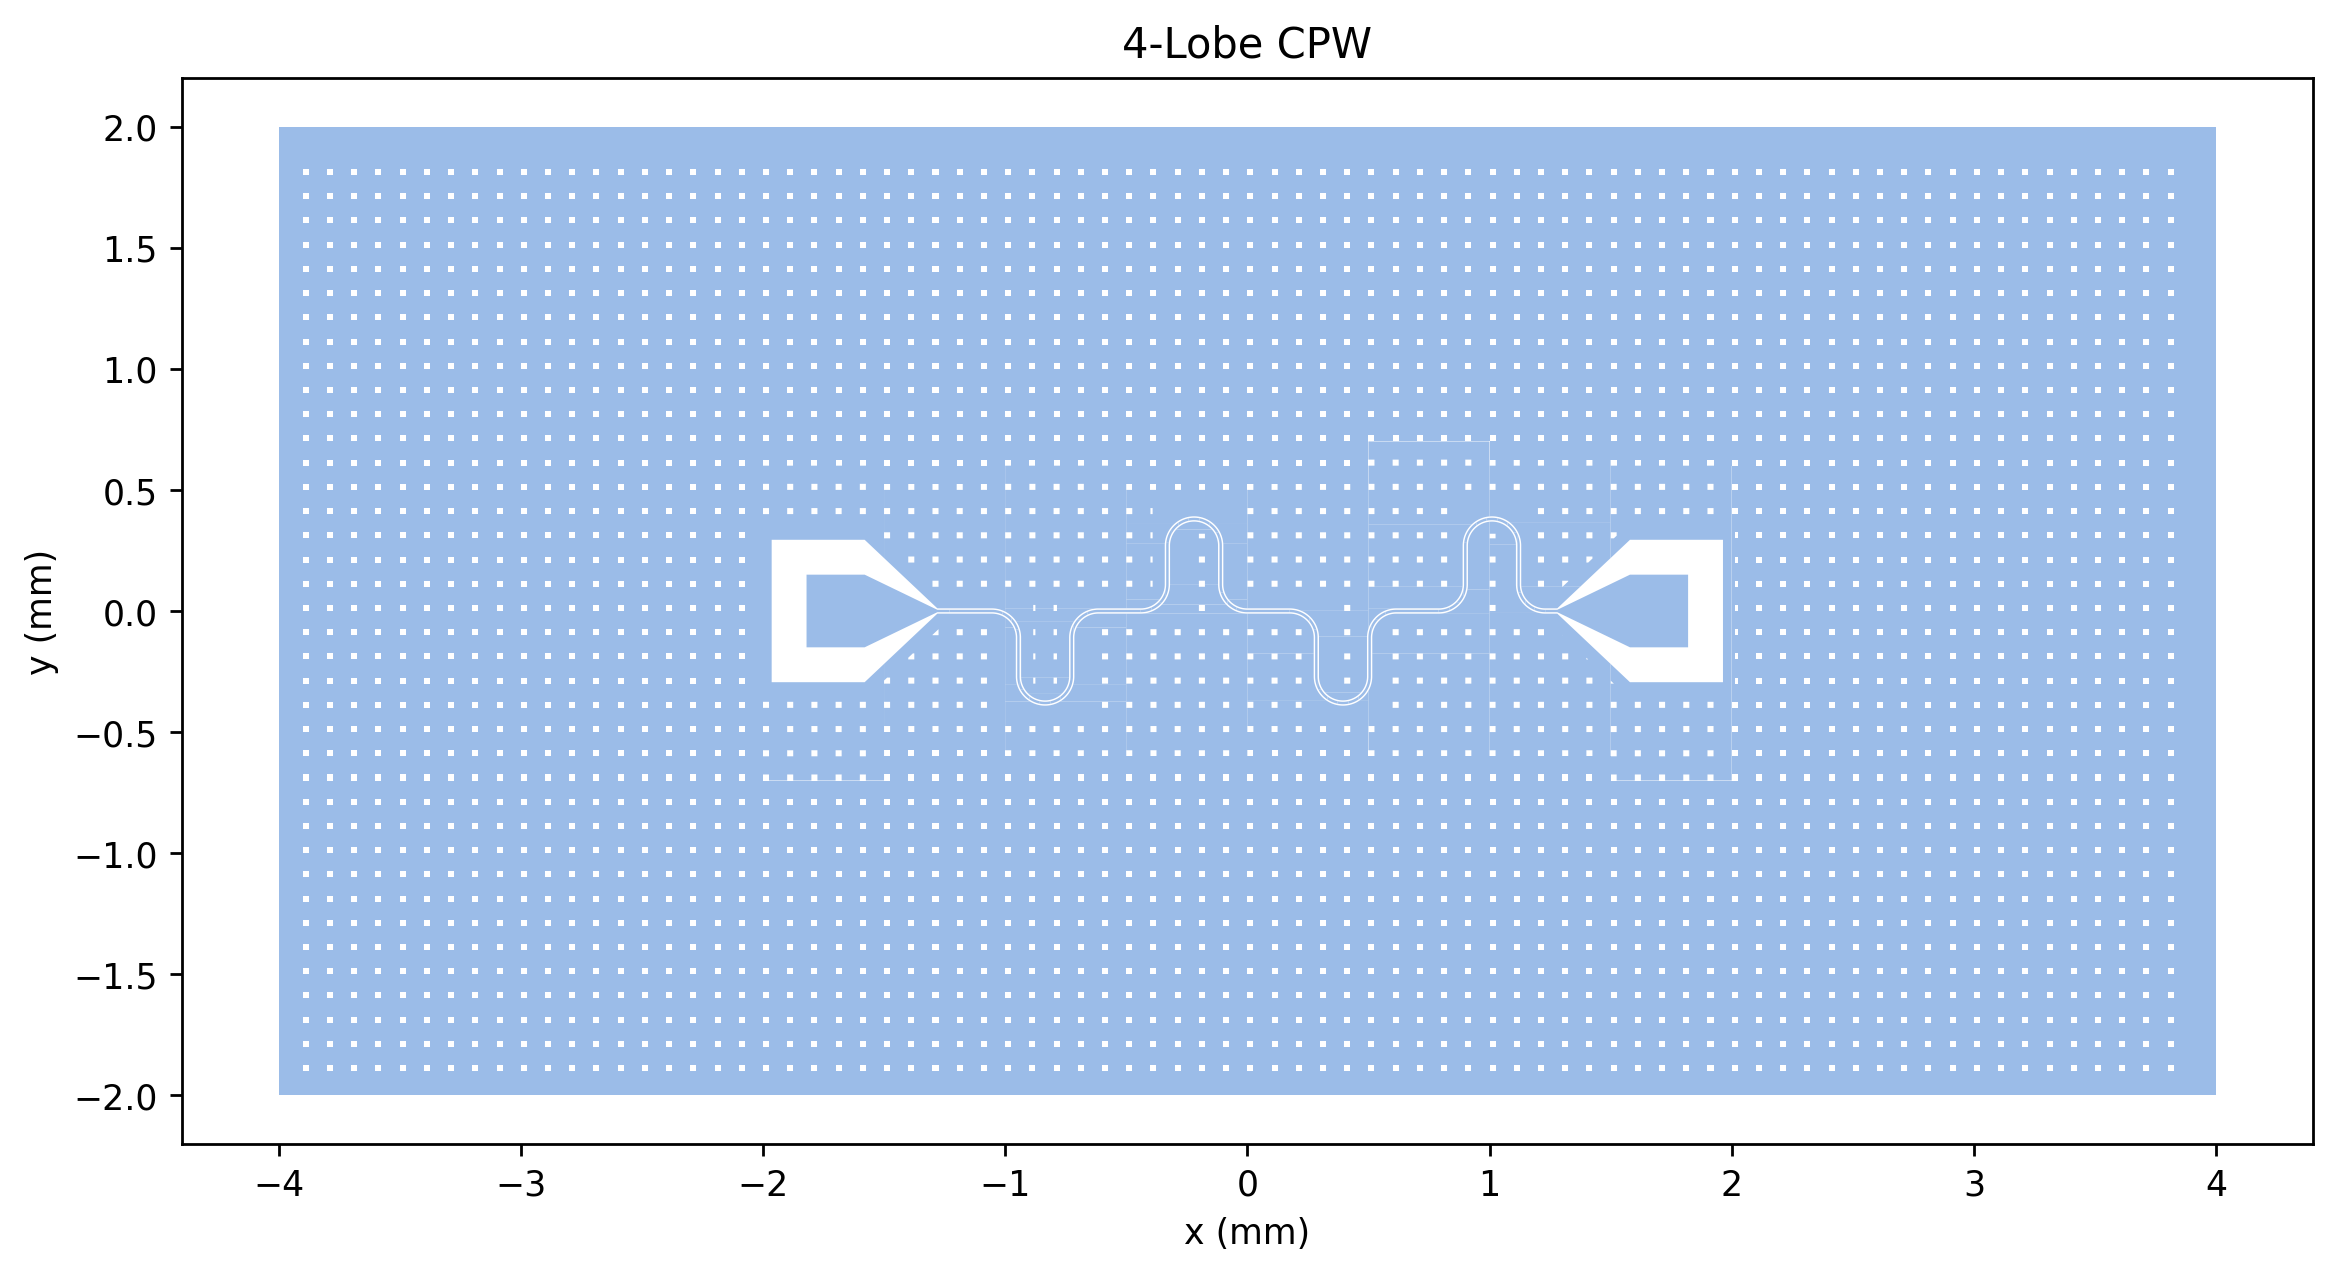

GDSII: four_lobe_cpw_quantum_metal.gds (228,586 bytes)
Layer 1: positive CPW metal and ground


/content/four_lobe_cpw_quantum_metal.gds

In [4]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""

gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
# Hole-center inset = 100 um edge clearance + half the default 25 um hole width.
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={METAL_LAYER: True})
# The native buffer also protects the inside of the 110 um circular bends.
gds_renderer.options.no_cheese.buffer = "50um"
gds_renderer.options.no_cheese.view_in_file = Dict(main={METAL_LAYER: False})

previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
assert export_status and out.is_file() and out.stat().st_size > 0

# Keep references only to cells present in the exported library.
cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds_renderer.lib.write_gds(str(out))

# --- Export Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {METAL_LAYER}
assert np.isclose(verified_gds.precision, 1e-9)

# --- In-Memory GDS Preview ---
fig, ax = plt.subplots(figsize=(11, 6), dpi=250)
ax.add_collection(PolyCollection(
    [polygon.points for polygon in exported_polygons],
    facecolor="#9bbce8", edgecolor="none", rasterized=True,
))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set(xlabel="x (mm)", ylabel="y (mm)", title=f"{N_LOBES}-Lobe CPW")
plt.show()

print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print(f"Layer {METAL_LAYER}: positive CPW metal and ground")
display(FileLink(str(out)))